# NYC Taxi Trip Analytics — Baseline Training

**Objective.** Predict a per-trip target for NYC Yellow Taxi rides from trip distance,
passenger count and cyclically-encoded pickup time.

The target is set by `data.target` in the config and defaults to **`fare_amount`** (USD).
Switch to `trip_duration_minutes` with a single override — the feature set is identical,
so the two runs are directly comparable. Note that `fare_amount` and
`trip_duration_minutes` are **both** excluded from the features: whichever is not the
target is unknown at pickup time, so using it would leak information the model would not
have when serving a live quote.

**Role of this notebook.** Orchestration only. Every piece of logic lives in the
installed `nyc_taxi` package and every hyperparameter lives in `configs/train.yaml`;
this notebook composes them, runs the training, and presents the results.

| Layer | Location |
|---|---|
| Hyperparameters & paths | `configs/train.yaml` |
| ETL (CSV → PostgreSQL) | `src/nyc_taxi/etl.py` |
| Dataset & DataLoaders | `src/nyc_taxi/data.py` |
| Model architecture | `src/nyc_taxi/model.py` |
| Training loop & W&B | `src/nyc_taxi/train.py` |
| SQL schema & analytics | `sql/` |

**Prerequisites**
1. `pip install -e ".[notebooks]"`
2. `POSTGRES_PASSWORD` exported (see `.env.example`).
3. `nyc-taxi-etl` has been run at least once, **or** a parquet cache exists at
   `data/clean_trips.parquet`.

**Execution.** Run all cells top to bottom. There are no out-of-order dependencies.

---
## 1. Environment setup

`autoreload` picks up edits to `src/` without restarting the kernel, so the
notebook and the package never drift apart during development.

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

In [2]:
from __future__ import annotations

import os
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from dotenv import load_dotenv

from nyc_taxi.baseline import bucket_mean, fit_one_linear_regression
from nyc_taxi.config import load_config, save_config
from nyc_taxi.data import TaxiDataModule
from nyc_taxi.model import build_model
from nyc_taxi.train import Trainer
from nyc_taxi.utils import count_parameters, get_device, seed_everything, setup_logging

warnings.filterwarnings("ignore", category=FutureWarning)
load_dotenv()  # Reads POSTGRES_PASSWORD, WANDB_* etc. from the local .env file.
setup_logging()

In [3]:
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "figure.figsize": (11, 4.5),
        "axes.titleweight": "semibold",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "font.size": 11,
    }
)
PALETTE = sns.color_palette("crest", n_colors=6)

---
## 2. Configuration

The single source of truth. Nothing below this cell hardcodes a hyperparameter —
to change an experiment, edit `configs/train.yaml` or pass a dotlist override here.

In [4]:
# NYC_TAXI_OVERRIDES lets CI (and a quick local smoke run) reconfigure this
# notebook without editing it, e.g.
#   NYC_TAXI_OVERRIDES="training.max_epochs=2 data.target=trip_duration_minutes"
OVERRIDES = [token for token in os.environ.get("NYC_TAXI_OVERRIDES", "").split() if token]

cfg = load_config(overrides=OVERRIDES)

seed_everything(cfg.project.seed)
device = get_device(cfg.training.device)

TARGET = cfg.data.target
UNIT = cfg.data.target_unit

print(f"Project        : {cfg.project.name}")
print(f"Seed           : {cfg.project.seed}")
print(f"Device         : {device}")
print(f"Target         : {TARGET} ({UNIT})")
print(f"Overrides      : {OVERRIDES or 'none'}")
print(f"Artifacts      : {cfg.project.artifact_dir}")

Project        : nyc-taxi-trip-analytics
Seed           : 42
Device         : cpu
Target         : fare_amount (USD)
Overrides      : none
Artifacts      : /home/andrzejkawinn/PycharmProjects/NYCTaxiTripAnalytics/models


In [5]:
from omegaconf import OmegaConf

print(OmegaConf.to_yaml({k: cfg[k] for k in ("model", "training", "optimizer", "scheduler")}))

model:
  name: TripDurationMLP
  hidden_dims:
  - 256
  - 128
  - 64
  dropout: 0.15
  activation: gelu
  use_batch_norm: true
  residual: true
training:
  max_epochs: 30
  device: auto
  criterion: huber
  huber_delta: 1.0
  gradient_clip_norm: 1.0
  accumulation_steps: 1
  use_amp: true
  early_stopping_patience: 5
  early_stopping_min_delta: 0.0001
  checkpoint_dir: /home/andrzejkawinn/PycharmProjects/NYCTaxiTripAnalytics/models/checkpoints
  checkpoint_name: TripDurationMLP_fare_amount_best.pt
  monitor_metric: val_rmse
  monitor_mode: min
  log_every_n_steps: 50
  progress_bar: auto
optimizer:
  name: adamw
  lr: 0.001
  weight_decay: 0.01
  betas:
  - 0.9
  - 0.999
  momentum: 0.9
scheduler:
  name: cosine
  warmup_epochs: 1
  min_lr: 1.0e-06
  step_size: 10
  gamma: 0.1
  patience: 2



---
## 3. Data

`TaxiDataModule.setup()` loads the clean table (parquet cache first, PostgreSQL
otherwise), engineers the cyclical time features, splits train/val/test with the
project seed, and fits the scalers **on the training split only**.

In [6]:
datamodule = TaxiDataModule(cfg).setup()

print(f"Input features : {datamodule.input_dim}")
print(f"Feature names  : {list(datamodule.spec.names)}")
print(
    f"Train / Val / Test : "
    f"{len(datamodule.dataset('train')):,} / "
    f"{len(datamodule.dataset('val')):,} / "
    f"{len(datamodule.dataset('test')):,}"
)

2026-09-04 23:55:23 | INFO     | nyc_taxi.data | Loading cached data from /home/andrzejkawinn/PycharmProjects/NYCTaxiTripAnalytics/data/clean_trips.parquet


2026-09-04 23:55:24 | INFO     | nyc_taxi.data | Split train -> 1,388,802 samples


2026-09-04 23:55:24 | INFO     | nyc_taxi.data | Split val   -> 297,601 samples


2026-09-04 23:55:24 | INFO     | nyc_taxi.data | Split test  -> 297,601 samples


2026-09-04 23:55:24 | INFO     | nyc_taxi.data | Feature contract: 6 inputs ['trip_distance', 'passenger_count', 'pickup_hour_sin', 'pickup_hour_cos', 'pickup_dayofweek_sin', 'pickup_dayofweek_cos']


Input features : 6
Feature names  : ['trip_distance', 'passenger_count', 'pickup_hour_sin', 'pickup_hour_cos', 'pickup_dayofweek_sin', 'pickup_dayofweek_cos']
Train / Val / Test : 1,388,802 / 297,601 / 297,601


### 3.1 Exploratory view of the target and features

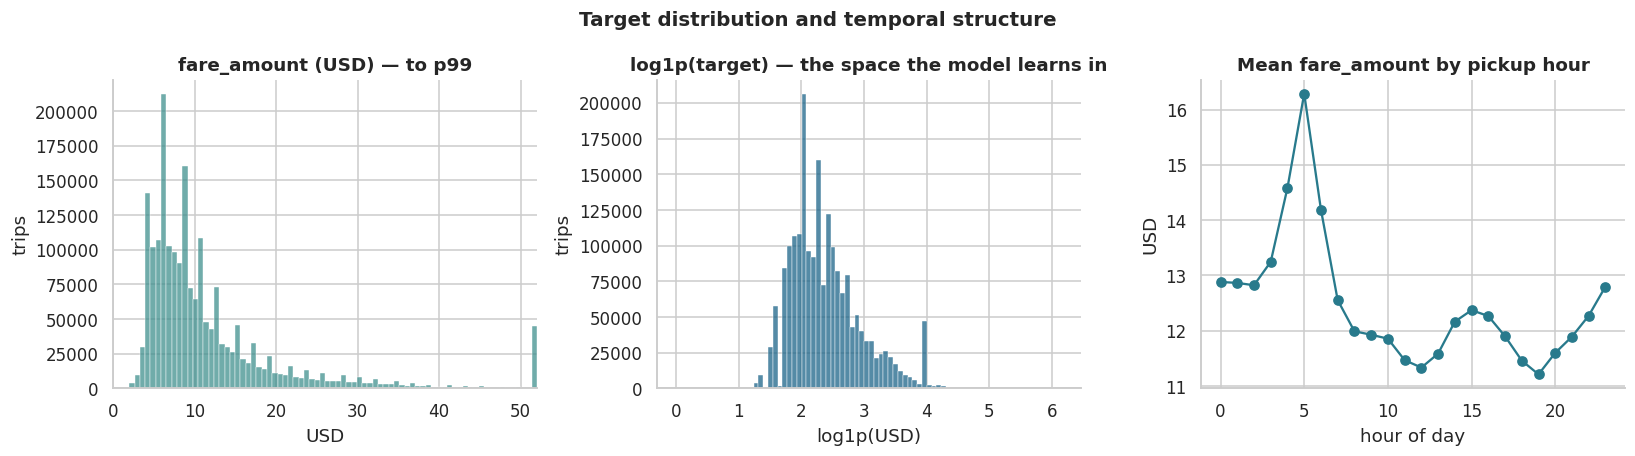

In [7]:
frame = datamodule.frame

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

# Bin only the visible range: binning the full range and then zooming with
# set_xlim leaves a handful of enormous bars inside the window.
upper = float(np.percentile(frame[TARGET], 99))
sns.histplot(frame[TARGET][frame[TARGET] <= upper], bins=80, ax=axes[0], color=PALETTE[2])
axes[0].set(title=f"{TARGET} ({UNIT}) — to p99", xlabel=UNIT, ylabel="trips")
axes[0].set_xlim(0, upper)

sns.histplot(np.log1p(frame[TARGET]), bins=80, ax=axes[1], color=PALETTE[4])
axes[1].set(
    title="log1p(target) — the space the model learns in", xlabel=f"log1p({UNIT})", ylabel="trips"
)

hourly = frame.groupby("pickup_hour")[TARGET].mean()
axes[2].plot(hourly.index, hourly.to_numpy(), marker="o", color=PALETTE[3])
axes[2].set(title=f"Mean {TARGET} by pickup hour", xlabel="hour of day", ylabel=UNIT)

fig.suptitle("Target distribution and temporal structure", fontsize=13, fontweight="semibold")
fig.tight_layout()
plt.show()

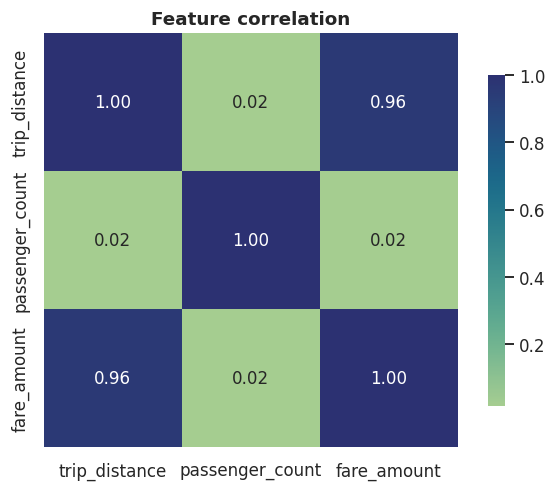

In [8]:
numeric_cols = [*cfg.data.numerical_features, TARGET]
correlation = frame[numeric_cols].corr()

fig, ax = plt.subplots(figsize=(6, 4.6))
sns.heatmap(
    correlation, annot=True, fmt=".2f", cmap="crest", square=True, cbar_kws={"shrink": 0.8}, ax=ax
)
ax.set_title("Feature correlation")
fig.tight_layout()
plt.show()

---
## 4. Model

`build_model` reads the `model` section of the config and is handed
`datamodule.input_dim`, so the architecture can never silently disagree with the
feature contract.

In [9]:
model = build_model(cfg, input_dim=datamodule.input_dim)

print(model)
print(f"\nTrainable parameters: {count_parameters(model):,}")

2026-09-04 23:55:27 | INFO     | nyc_taxi.model | Built TripDurationMLP | input_dim=6 | trainable params=43,457


TripDurationMLP(
  input_dim=6, hidden_dims=[256, 128, 64], output_dim=1, params=43,457
  (backbone): Sequential(
    (0): MLPBlock(
      (linear): Linear(in_features=6, out_features=256, bias=False)
      (norm): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (activation): GELU(approximate='none')
      (dropout): Dropout(p=0.15, inplace=False)
    )
    (1): MLPBlock(
      (linear): Linear(in_features=256, out_features=128, bias=False)
      (norm): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (activation): GELU(approximate='none')
      (dropout): Dropout(p=0.15, inplace=False)
    )
    (2): MLPBlock(
      (linear): Linear(in_features=128, out_features=64, bias=False)
      (norm): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (activation): GELU(approximate='none')
      (dropout): Dropout(p=0.15, inplace=False)
    )
  )
  (h

---
## 5. Training

One call. The `Trainer` owns the epoch loop, AMP, gradient clipping, LR
scheduling, early stopping, checkpointing and Weights & Biases logging.

> Set `wandb.enabled=false` (or `WANDB_MODE=offline`) to run without tracking.

In [10]:
trainer = Trainer(model=model, datamodule=datamodule, cfg=cfg)
history = trainer.fit()

print(f"Completed {len(history)} epoch(s).")

2026-09-04 23:55:28 | INFO     | nyc_taxi.train | Trainer ready | device=cpu | amp=False | params=43,457


2026-09-04 23:55:28 | INFO     | nyc_taxi.train | W&B logging is disabled (wandb.enabled=false).


2026-09-04 23:55:28 | INFO     | nyc_taxi.train | Training for up to 30 epoch(s) on cpu


2026-09-04 23:55:56 | INFO     | nyc_taxi.train | Epoch 001/030 | train_loss=0.0507 | val_loss=0.0269 | val_rmse=4.409 USD | val_mae=1.182 USD | val_r2=0.8208 | lr=1.00e-03 | 28.2s


2026-09-04 23:56:23 | INFO     | nyc_taxi.train | Epoch 002/030 | train_loss=0.0333 | val_loss=0.0263 | val_rmse=3.230 USD | val_mae=1.148 USD | val_r2=0.9038 | lr=9.97e-04 | 26.5s


2026-09-04 23:56:53 | INFO     | nyc_taxi.train | Epoch 003/030 | train_loss=0.0318 | val_loss=0.0257 | val_rmse=2.957 USD | val_mae=1.121 USD | val_r2=0.9194 | lr=9.88e-04 | 30.0s


... (3 outputs left out)

2026-09-04 23:59:10 | INFO     | nyc_taxi.train | Epoch 007/030 | train_loss=0.0296 | val_loss=0.0254 | val_rmse=3.460 USD | val_mae=1.100 USD | val_r2=0.8897 | lr=8.98e-04 | 37.1s


2026-09-04 23:59:43 | INFO     | nyc_taxi.train | Epoch 008/030 | train_loss=0.0293 | val_loss=0.0255 | val_rmse=3.045 USD | val_mae=1.099 USD | val_r2=0.9145 | lr=8.63e-04 | 32.6s


2026-09-04 23:59:43 | INFO     | nyc_taxi.train | Early stopping at epoch 8: val_rmse did not improve for 5 epoch(s). Best val_rmse=2.9574 at epoch 3.


Completed 8 epoch(s).


---
## 6. Results

### 6.1 Learning curves

In [11]:
history_df = pd.DataFrame(history.to_dict()).set_index("epoch")
history_df.tail()

,train_loss,val_loss,val_rmse,val_mae,val_r2,learning_rate,epoch_seconds
epoch,,,,,,,
4.0,0.030996,0.025579,3.170100,1.112282,0.907352,0.000974,34.671020
5.0,0.030449,0.025453,3.311211,1.127608,0.898920,0.000954,33.618821
6.0,0.030051,0.025496,3.105416,1.107219,0.911094,0.000929,31.760441
7.0,0.029578,0.025429,3.459577,1.100368,0.889659,0.000898,37.117485
8.0,0.029326,0.025506,3.045072,1.098636,0.914516,0.000863,32.608492


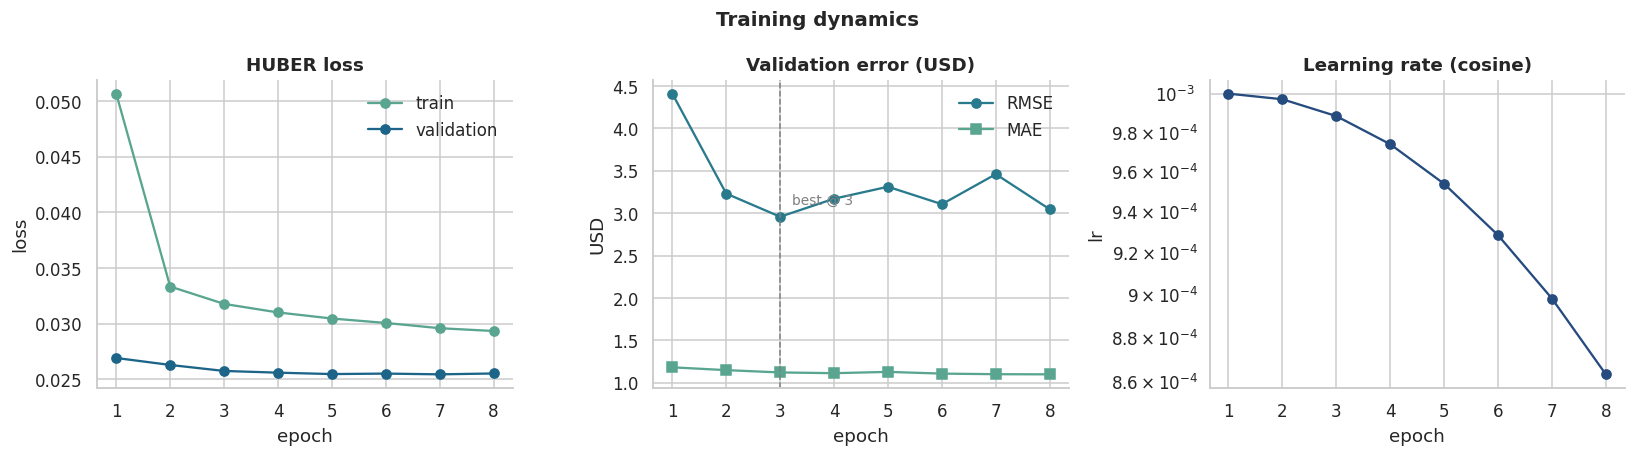

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

axes[0].plot(
    history_df.index, history_df["train_loss"], label="train", color=PALETTE[1], marker="o"
)
axes[0].plot(
    history_df.index, history_df["val_loss"], label="validation", color=PALETTE[4], marker="o"
)
axes[0].set(title=f"{cfg.training.criterion.upper()} loss", xlabel="epoch", ylabel="loss")
axes[0].legend(frameon=False)

axes[1].plot(history_df.index, history_df["val_rmse"], color=PALETTE[3], marker="o", label="RMSE")
axes[1].plot(history_df.index, history_df["val_mae"], color=PALETTE[1], marker="s", label="MAE")
best_epoch = int(history_df["val_rmse"].idxmin())
axes[1].axvline(best_epoch, ls="--", lw=1, color="grey")
axes[1].annotate(
    f"best @ {best_epoch}",
    (best_epoch, history_df["val_rmse"].min()),
    textcoords="offset points",
    xytext=(8, 8),
    fontsize=9,
    color="grey",
)
axes[1].set(title=f"Validation error ({UNIT})", xlabel="epoch", ylabel=UNIT)
axes[1].legend(frameon=False)

axes[2].plot(history_df.index, history_df["learning_rate"], color=PALETTE[5], marker="o")
axes[2].set(title=f"Learning rate ({cfg.scheduler.name})", xlabel="epoch", ylabel="lr")
axes[2].set_yscale("log")

fig.suptitle("Training dynamics", fontsize=13, fontweight="semibold")
fig.tight_layout()
plt.show()

### 6.2 Held-out test evaluation

`evaluate` restores the best checkpoint first, so these numbers describe the
selected model rather than the final epoch.

In [13]:
test_metrics = trainer.evaluate(split="test", restore_best=True)

pd.DataFrame(
    [
        {"metric": f"RMSE ({UNIT})", "value": test_metrics["rmse"]},
        {"metric": f"MAE ({UNIT})", "value": test_metrics["mae"]},
        {"metric": "R²", "value": test_metrics["r2"]},
        {"metric": f"{cfg.training.criterion.upper()} loss", "value": test_metrics["loss"]},
    ]
).style.format({"value": "{:.4f}"}).hide(axis="index").set_caption("Test-set performance")

2026-09-04 23:59:43 | INFO     | nyc_taxi.train | Restored checkpoint from /home/andrzejkawinn/PycharmProjects/NYCTaxiTripAnalytics/models/checkpoints/TripDurationMLP_fare_amount_best.pt (epoch 3)


2026-09-04 23:59:45 | INFO     | nyc_taxi.train | TEST | loss=0.0262 | rmse=3.060 USD | mae=1.126 USD | r2=0.9150


metric,value
RMSE (USD),3.0599
MAE (USD),1.1264
R²,0.9150
HUBER loss,0.0262


### 6.3 Prediction quality

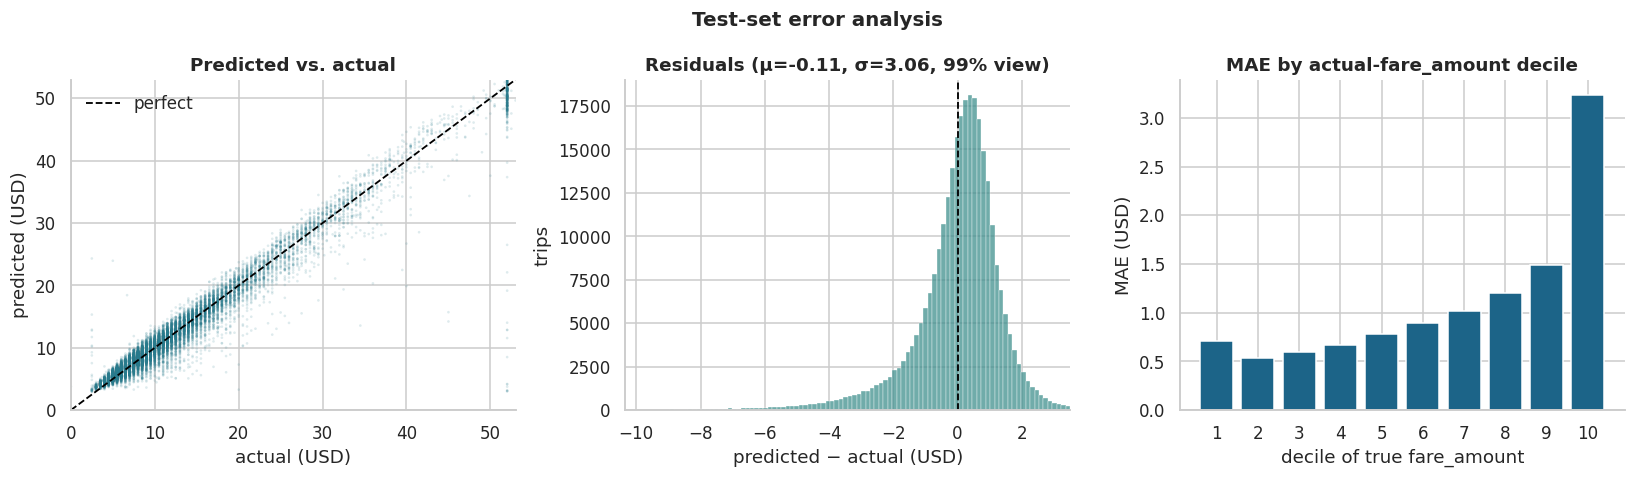

In [14]:
y_pred, y_true = trainer.predict(datamodule.test_dataloader())
residuals = y_pred - y_true

fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))

rng = np.random.default_rng(cfg.project.seed)
sample = rng.choice(len(y_true), size=min(20_000, len(y_true)), replace=False)
axes[0].scatter(
    y_true[sample], y_pred[sample], s=3, alpha=0.15, color=PALETTE[3], edgecolors="none"
)
limit = float(np.percentile(y_true, 99.5))
axes[0].plot([0, limit], [0, limit], ls="--", lw=1.2, color="black", label="perfect")
axes[0].set(
    title="Predicted vs. actual",
    xlabel=f"actual ({UNIT})",
    ylabel=f"predicted ({UNIT})",
    xlim=(0, limit),
    ylim=(0, limit),
)
axes[0].legend(frameon=False)

# μ and σ are computed on ALL residuals; only the plotted range is trimmed.
low, high = np.percentile(residuals, [0.5, 99.5])
visible = residuals[(residuals >= low) & (residuals <= high)]
sns.histplot(visible, bins=100, ax=axes[1], color=PALETTE[2])
axes[1].axvline(0, ls="--", lw=1.2, color="black")
axes[1].set(
    title=f"Residuals (μ={residuals.mean():.2f}, σ={residuals.std():.2f}, 99% view)",
    xlabel=f"predicted − actual ({UNIT})",
    ylabel="trips",
)
axes[1].set_xlim(low, high)

bins = np.percentile(y_true, np.linspace(0, 100, 11))
bin_index = np.clip(np.digitize(y_true, bins[1:-1]), 0, 9)
bin_mae = [np.abs(residuals[bin_index == i]).mean() for i in range(10)]
axes[2].bar(range(1, 11), bin_mae, color=PALETTE[4])
axes[2].set(
    title=f"MAE by actual-{TARGET} decile",
    xlabel=f"decile of true {TARGET}",
    ylabel=f"MAE ({UNIT})",
)
axes[2].set_xticks(range(1, 11))

fig.suptitle("Test-set error analysis", fontsize=13, fontweight="semibold")
fig.tight_layout()
plt.show()

### 6.4 Comparison against non-neural baselines

Both baselines are fitted on the **train** split and scored on the **same test
split** as the MLP, via `nyc_taxi.baseline`:

* the `(dayofweek, hour)` bucket mean -- the train/test version of the in-sample,
  descriptive figure in `sql/02_analytics.sql` (query 6);
* a linear regression on `trip_distance` alone -- the bar the MLP must clear, since
  the tariff is mostly a per-mile price.

In [ ]:
RMSE_COL = f"RMSE ({UNIT})"
splits = datamodule.splits

bucket_rmse, bucket_r2 = bucket_mean(splits["train"], splits["test"], TARGET)
linear_rmse, linear_r2 = fit_one_linear_regression(splits, TARGET)

comparison = pd.DataFrame(
    {
        "model": ["(dayofweek, hour) mean", "linear (trip_distance)", cfg.model.name],
        RMSE_COL: [bucket_rmse, linear_rmse, test_metrics["rmse"]],
        "R²": [bucket_r2, linear_r2, test_metrics["r2"]],
    }
)
comparison["RMSE improvement vs linear"] = 1 - comparison[RMSE_COL] / linear_rmse

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.barh(comparison["model"], comparison[RMSE_COL], color=[PALETTE[1], PALETTE[2], PALETTE[4]])
for y, value in enumerate(comparison[RMSE_COL]):
    ax.text(value, y, f"  {value:.2f}", va="center", fontsize=10)
ax.set(title=f"Test RMSE ({UNIT}) — lower is better", xlabel=UNIT)
ax.invert_yaxis()
fig.tight_layout()
plt.show()

comparison.style.format(
    {RMSE_COL: "{:.3f}", "R²": "{:.4f}", "RMSE improvement vs linear": "{:+.1%}"}
).hide(axis="index")

---
## 7. Artifacts

The resolved config is written next to the checkpoint so this exact run can be
reproduced from disk alone.

In [16]:
checkpoint_path = trainer.checkpoint_path
config_path = save_config(cfg, Path(cfg.training.checkpoint_dir) / "resolved_config.yaml")

print(f"Best checkpoint : {checkpoint_path}  ({checkpoint_path.stat().st_size / 1e6:.2f} MB)")
print(f"Resolved config : {config_path}")

Best checkpoint : /home/andrzejkawinn/PycharmProjects/NYCTaxiTripAnalytics/models/checkpoints/TripDurationMLP_fare_amount_best.pt  (0.55 MB)
Resolved config : /home/andrzejkawinn/PycharmProjects/NYCTaxiTripAnalytics/models/checkpoints/resolved_config.yaml


---
## 8. Summary & next steps

**Outcome.** The residual MLP is compared against the `(dayofweek, hour)` mean
heuristic on a held-out test split; the tables and figures above report RMSE, MAE
and R² in the target's own unit, all restored from the best checkpoint rather than
the last epoch.

Run `python scripts/compare_targets.py` to benchmark both candidate targets
side by side from the same feature set.

**Reproduce headlessly**

```bash
nyc-taxi-etl                                  # CSV → PostgreSQL
nyc-taxi-train training.max_epochs=30         # this notebook, without the plots
```

**Next experiments**
- Add pickup/dropoff geography (`PULocationID`/`DOLocationID`) — currently dropped by the ETL projection.
- Sweep `model.hidden_dims`, `model.dropout` and `optimizer.lr` with a W&B sweep.
- Benchmark against gradient boosting to confirm the deep model earns its complexity.